In [1]:
%run "/home/usriniva/Desktop/Phd/Epigenetics/Simulations/New_Hanna_eqns/Evolve_Transgenerational_memory/simulation/interactive_jupyter_notebooks/simulation_prereqs/impport_packages.ipynb"    #import all necessary packages - numpy, pandas etc
%run "/home/usriniva/Desktop/Phd/Epigenetics/Simulations/New_Hanna_eqns/Evolve_Transgenerational_memory/simulation/interactive_jupyter_notebooks/simulation_prereqs/simulation_class.ipynb"    #import all necessary packages - numpy, pandas etc
%run "/home/usriniva/Desktop/Phd/Epigenetics/Simulations/New_Hanna_eqns/Evolve_Transgenerational_memory/simulation/interactive_jupyter_notebooks/simulation_prereqs/create_world.ipynb"   #import all necessary packages - numpy, pandas etc
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde


Done.


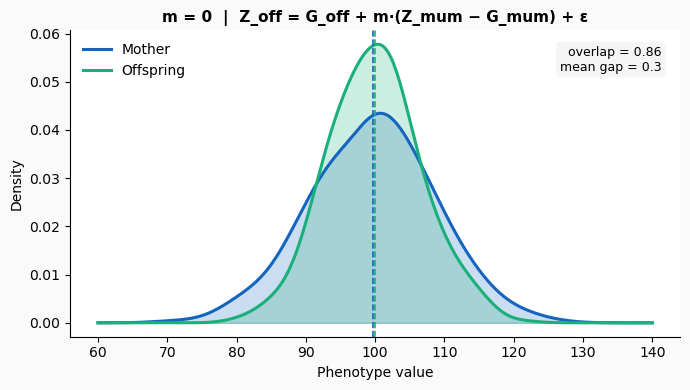

In [38]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde

rng = np.random.default_rng(42)

n      = 500
mu_pop = 100
VA     = 36
VE     = 36
m      = 0      # ← change this

G_mum = rng.normal(mu_pop, np.sqrt(VA), n)
E_mum = rng.normal(0,      np.sqrt(VE), n)
Z_mum = G_mum + E_mum + rng.normal(0, 3, n)
G_off = G_mum + rng.normal(0, 3, n)
Z_off = G_mum + m * (Z_mum-G_mum) + rng.normal(0, 3, n)

x = np.linspace(60, 140, 400)
y_m = gaussian_kde(Z_mum, bw_method=0.35)(x)
y_o = gaussian_kde(Z_off, bw_method=0.35)(x)
overlap = np.trapezoid(np.minimum(y_m, y_o), x)

fig, ax = plt.subplots(figsize=(7, 4), facecolor="#FAFAFA")
ax.set_facecolor("white")

ax.fill_between(x, y_m, alpha=0.22, color="#1565C0")
ax.fill_between(x, y_o, alpha=0.22, color="#1baf7a")
ax.plot(x, y_m, color="#1565C0", lw=2.2, label="Mother")
ax.plot(x, y_o, color="#1baf7a", lw=2.2, label="Offspring")
ax.axvline(Z_mum.mean(), color="#1565C0", lw=1.2, ls="--")
ax.axvline(Z_off.mean(), color="#1baf7a", lw=1.2, ls="--")

ax.text(0.97, 0.95,
        f"overlap = {overlap:.2f}\nmean gap = {abs(Z_off.mean()-Z_mum.mean()):.1f}",
        transform=ax.transAxes, ha="right", va="top", fontsize=9,
        bbox=dict(boxstyle="round,pad=0.3", fc="#F5F5F5", ec="none"))

ax.set_title(f"m = {m}  |  Z_off = G_off + m·(Z_mum − G_mum) + ε",
             fontsize=11, fontweight="bold")
ax.set_xlabel("Phenotype value", fontsize=10)
ax.set_ylabel("Density", fontsize=10)
ax.legend(fontsize=10, frameon=False)
for sp in ["top", "right"]:
    ax.spines[sp].set_visible(False)

plt.tight_layout()

print("Done.")

In [41]:
dev = Z_mum-G_mum
dev.mean()

np.float64(-0.2797107849783464)

Done.


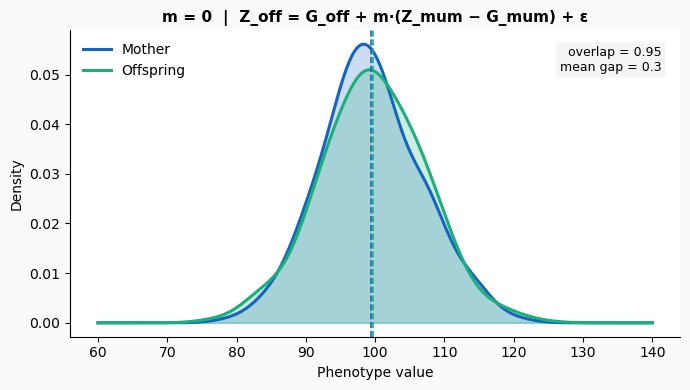

In [45]:
rng = np.random.default_rng(42)

n      = 500
mu_pop = 100
VA     = 36
VE     = 36
m      = 0      # ← change this

G_mum = rng.normal(mu_pop, np.sqrt(VA), n)
E_mum = rng.normal(0,      np.sqrt(VE), n)
Z_mum = G_mum + E_mum + rng.normal(0, 3, n)

G_off = G_mum + rng.normal(0, 3, n)
Z_off = G_off + m * (Z_mum-G_mum) + rng.normal(0, 3, n)

G_grand = G_off  + rng.normal(0, 3, n)
Z_grand =  G_grand + m * (Z_off-G_off) + rng.normal(0, 3, n)



x = np.linspace(60, 140, 400)
y_m = gaussian_kde(Z_off, bw_method=0.35)(x)
y_o = gaussian_kde(Z_grand, bw_method=0.35)(x)
overlap = np.trapezoid(np.minimum(y_m, y_o), x)

fig, ax = plt.subplots(figsize=(7, 4), facecolor="#FAFAFA")
ax.set_facecolor("white")

ax.fill_between(x, y_m, alpha=0.22, color="#1565C0")
ax.fill_between(x, y_o, alpha=0.22, color="#1baf7a")
ax.plot(x, y_m, color="#1565C0", lw=2.2, label="Mother")
ax.plot(x, y_o, color="#1baf7a", lw=2.2, label="Offspring")
ax.axvline(Z_off.mean(), color="#1565C0", lw=1.2, ls="--")
ax.axvline(Z_grand.mean(), color="#1baf7a", lw=1.2, ls="--")

ax.text(0.97, 0.95,
        f"overlap = {overlap:.2f}\nmean gap = {abs(Z_grand.mean()-Z_off.mean()):.1f}",
        transform=ax.transAxes, ha="right", va="top", fontsize=9,
        bbox=dict(boxstyle="round,pad=0.3", fc="#F5F5F5", ec="none"))

ax.set_title(f"m = {m}  |  Z_off = G_off + m·(Z_mum − G_mum) + ε",
             fontsize=11, fontweight="bold")
ax.set_xlabel("Phenotype value", fontsize=10)
ax.set_ylabel("Density", fontsize=10)
ax.legend(fontsize=10, frameon=False)
for sp in ["top", "right"]:
    ax.spines[sp].set_visible(False)

plt.tight_layout()

print("Done.")

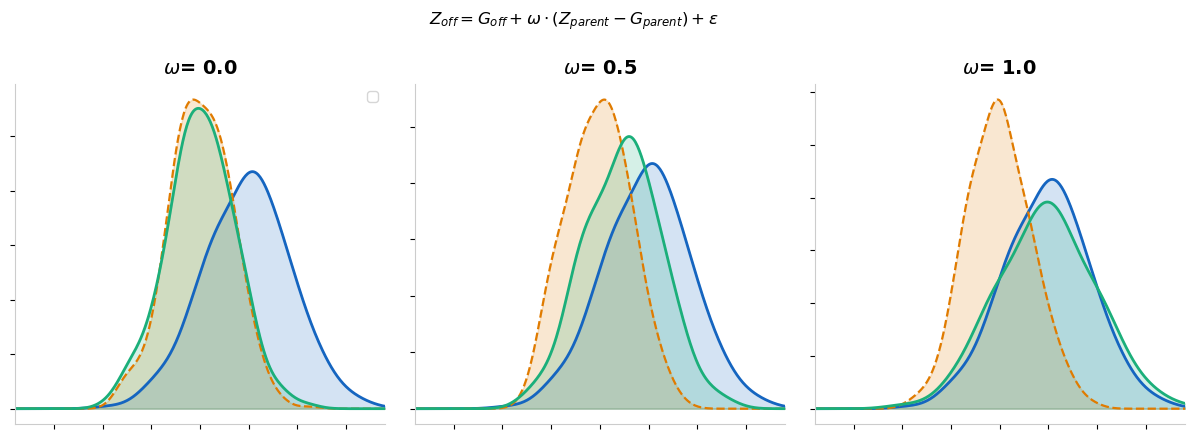

In [9]:

rng = np.random.default_rng(42)

n      = 500
mu_pop = 100
epi_pop = 10
VA     = 36
VE     = 36

m_vals = [0.0, 0.5, 1.0]

# Shared parent generation (same across all panels)

fig, axes = plt.subplots(1, 3, figsize=(13, 5),
                          sharex=True)
fig.subplots_adjust(wspace=0.08, left=0.07, right=0.97, top=0.82, bottom=0.14)

x = np.linspace(60, 140, 400)

BLUE   = "#1565C0"   # mother Z_mum
ORANGE = "#E07B00"   # offspring G_off (genetic only)
GREEN  = "#1baf7a"   # offspring Z_off (with maternal effects)

# KDE for Z_mum — same in every panel

G_mum = rng.normal(mu_pop, np.sqrt(VA), n)
E_mum = rng.normal(epi_pop, np.sqrt(VE), n)        # mean-zero
Z_mum = G_mum + E_mum + rng.normal(0, 3, n)
y_mum = gaussian_kde(Z_mum, bw_method=0.35)(x)

for ax, m in zip(axes, m_vals):
    # only offspring vary across panels
    G_off = G_mum + rng.normal(0, 3, n)
    Z_off = G_off + m * (Z_mum - G_mum) + rng.normal(0, 3, n)


    # Offspring
    G_off = G_mum + rng.normal(0, 3, n)
    Z_off = G_off + m * (Z_mum - G_mum) + rng.normal(0, 3, n)

    y_goff = gaussian_kde(G_off, bw_method=0.35)(x)
    y_zoff = gaussian_kde(Z_off, bw_method=0.35)(x)

    # Mother Z_mum
    ax.fill_between(x, y_mum,  alpha=0.18, color=BLUE)
    ax.plot(x, y_mum,  color=BLUE,   lw=2.0, label="Mother $Z_{parent}$")

    # Offspring genetic baseline G_off
    ax.fill_between(x, y_goff, alpha=0.18, color=ORANGE)
    ax.plot(x, y_goff, color=ORANGE, lw=1.6, ls="--", label="Offspring $G_{off}$")

    # Offspring phenotype Z_off
    ax.fill_between(x, y_zoff, alpha=0.18, color=GREEN)
    ax.plot(x, y_zoff, color=GREEN,  lw=2.0, label="Offspring $Z_{off}$")

    # Variance annotations
    var_mum  = round(Z_mum.var(), 1)
    var_goff = round(G_off.var(), 1)
    var_zoff = round(Z_off.var(), 1)

    #ax.text(0.97, 0.97,
     #       f"Var($Z_{{mum}}$)  = {var_mum}\n"
     #       f"Var($G_{{off}}$)  = {var_goff}\n"
    #        f"Var($Z_{{off}}$) = {var_zoff}",
     #      transform=ax.transAxes, ha="right", va="top",
   #         fontsize=8.5, color="#333333", family="monospace",
    #       bbox=dict(boxstyle="round,pad=0.35", fc="#F5F5F5", ec="none"))

    ax.set_title(rf"$\omega$= {m:.1f}", fontsize=14, fontweight="bold", pad=8)
    ax.set_xlabel("", fontsize=10)
    
    ax.set_xlim(62, 138)
    ax.set_xticklabels([])
    ax.set_yticklabels([])
    ax.tick_params(labelsize=8)
    for sp in ["top", "right"]:
        ax.spines[sp].set_visible(False)
    ax.spines["left"].set_color("#CCCCCC")
    ax.spines["bottom"].set_color("#CCCCCC")

axes[0].set_ylabel("", fontsize=10)
axes[0].legend("")


fig.suptitle(
    #"How m transfers maternal environmental variance into offspring phenotype\n"
    r"$Z_{off} = G_{off} + \omega \cdot (Z_{parent} - G_{parent}) + \varepsilon$",
    fontsize=12, fontweight="bold", y=0.97
   )

#fig.text(0.5, 0.01,
     #    r"At m=0: $Var(Z_{off}) = V_A + \sigma^2_\varepsilon$  |  "
     #    r"At m=1: $Var(Z_{off}) \approx Var(Z_{mum})$  |  "
     #    r"Intermediate m: $m^2 \cdot V_E$ added to offspring variance",
      #   ha="center", fontsize=8.5, color="#555555")


plt.savefig('/home/usriniva/Desktop/Phd/Epigenetics/Simulations/New_Hanna_eqns/Evolve_Transgenerational_memory/Plot_results/plot_report/figures_svg/10k/memory_schem.png',
            transparent=True)